<a href="https://colab.research.google.com/github/JuanCg42/Deteccion_de_Huecos_en_Carreteras_CNN/blob/main/Entrenamiento/Detecci%C3%B3n_de_Huecos_en_Carreteras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Se agregan librerias que son importantes para el proyecto
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import drive
from PIL import Image #Se utiliza PIL para poder poder obtener imagenes y agregarlas al informe
import pandas as pd # Se Utiliza para poder general las tablas y agregarlas al informe

drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/huecos/huecos.zip" -d "/content/huecos"


Mounted at /content/drive


In [2]:
#Se revisan las carpetas que hay dentro de la carpeta principal, para que se puedan identificar todos los tipo que contienen este DataSet.
ruta_dataset = "/content/huecos/huecos"
print("Clases:", os.listdir(ruta_dataset))

Clases: ['Normal', 'Surface Erosion', 'Crack', 'Pothole']


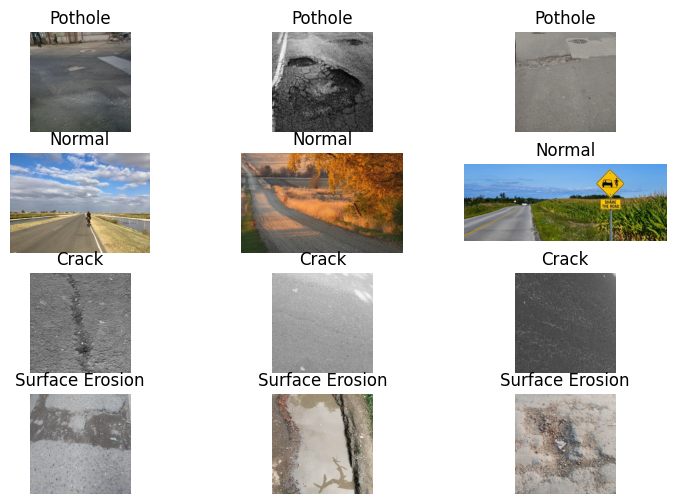

In [3]:
clases = ["Pothole", "Normal", "Crack", "Surface Erosion"]

plt.figure(figsize=(12,6))
for i, clase in enumerate(clases):
    carpeta = ruta_dataset + "/" + clase
    archivos = os.listdir(carpeta)
    for j in range(3):
        imagen = Image.open(carpeta + "/" + archivos[j])
        plt.subplot(4, 4, i*4 + j + 1)
        plt.imshow(imagen)
        plt.title(clase)
        plt.axis("off")
plt.show()

In [4]:
train_ds, test_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_dataset,
    validation_split=0.15,
    subset="both",
    seed=42,
    image_size=(224, 224), #Las redimensionamos debido a que si se reducen se puede hacer un entrenamiento más rapido
    batch_size=2000)

class_names = train_ds.class_names
print("Clases:", class_names)

X_train, y_train = next(iter(train_ds)) # se sacan las imagenes, etiquetas de entrenamiento
X_test, y_test = next(iter(test_ds))    # Y las de prueba

X_train = X_train.numpy().astype("uint8")
y_train = y_train.numpy()
X_test = X_test.numpy().astype("uint8")
y_test = y_test.numpy()

print("Datos de entrenamiento", X_train.shape, y_train.shape)
print("Datos de prueba", X_test.shape, y_test.shape)

Found 1882 files belonging to 4 classes.
Using 1600 files for training.
Using 282 files for validation.
Clases: ['Crack', 'Normal', 'Pothole', 'Surface Erosion']
Datos de entrenamiento (1600, 224, 224, 3) (1600,)
Datos de prueba (282, 224, 224, 3) (282,)


In [5]:


corte = int(len(y_train) * 0.8)
y_entrenamiento = y_train[:corte]
y_validacion = y_train[corte:]

tabla = pd.DataFrame({
    "Clase": class_names,
    "Entrenamiento": np.bincount(y_entrenamiento),
    "Validación": np.bincount(y_validacion),
    "Prueba": np.bincount(y_test)})
tabla["Total"] = tabla["Entrenamiento"] + tabla["Validación"] + tabla["Prueba"]
tabla

,Clase,Entrenamiento,Validación,Prueba,Total
0,Crack,309,105,64,478
1,Normal,238,60,54,352
2,Pothole,287,55,59,401
3,Surface Erosion,446,100,105,651


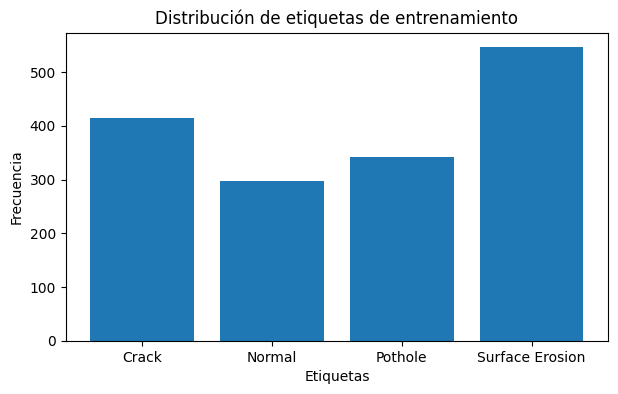

In [6]:
#Diferente Presentación- en grafico de barras
values_train, coun_train = np.unique(y_train, return_counts=True)
plt.figure(figsize=(7,4))
plt.bar(values_train, coun_train)
plt.title("Distribución de etiquetas de entrenamiento")
plt.xlabel("Etiquetas")
plt.ylabel("Frecuencia")
plt.xticks(values_train, class_names)
plt.savefig("distribucion_clases.png")
plt.show()

In [7]:
from scipy.signal import convolve2d # Se importa para la convolucón

idx_hueco = np.where(y_train == class_names.index("Pothole"))[0][0]
img = X_train[idx_hueco].mean(axis=2) # convierte la imagen RGB a escala de grises promediando cada canal

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]]) #Filtro para buscar que tanto cambia el brillo de izquierda a derecha, con el fin de encontrar el contorno de ese objeto

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]]) #Filtro para buscar que tanto cambia el brillo de Arriba hacia abajo, con el fin de encontrar el contorno de ese objeto

laplaciano = np.array([[0,  1, 0],
                       [1, -4, 1],
                       [0,  1, 0]]) #Filtro para buscar que tanto cambia el brillo en todas las direcciones, con el fin de encontrar el resto del contorno de ese objeto

borde_x = convolve2d(img, sobel_x, mode="same") #Garantizamos que la salida sea del mismo tamaño que la imagen
borde_y = convolve2d(img, sobel_y, mode="same")
borde_lap = convolve2d(img, laplaciano, mode="same")



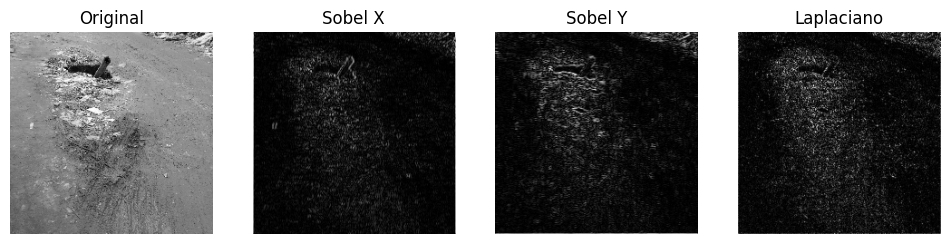

In [8]:
plt.figure(figsize=(12,3))
plt.subplot(1, 4, 1); plt.imshow(img, cmap="gray"); plt.title("Original"); plt.axis("off")
plt.subplot(1, 4, 2); plt.imshow(np.abs(borde_x), cmap="gray"); plt.title("Sobel X"); plt.axis("off")
plt.subplot(1, 4, 3); plt.imshow(np.abs(borde_y), cmap="gray"); plt.title("Sobel Y"); plt.axis("off")
plt.subplot(1, 4, 4); plt.imshow(np.abs(borde_lap), cmap="gray"); plt.title("Laplaciano"); plt.axis("off")
plt.savefig("convolucion_filtros.png")
plt.show()

In [9]:
 # pasamos los pixeles que teniamos de 0 a 255 a decimales de 0 a 1, la red aprende mejor con valores de 0 a 1, con valores tan grande puede haber mucho más descontrol.
train_images = X_train.astype("float32") / 255
test_images = X_test.astype("float32") / 255

print("Imagenes de entrenamiento", train_images.shape, "- valor min:", train_images.min(), "- valor max:", train_images.max())
print("Imagenes de prueba", test_images.shape)

Imagenes de entrenamiento (1600, 224, 224, 3) - valor min: 0.0 - valor max: 1.0
Imagenes de prueba (282, 224, 224, 3)


In [10]:
from keras.utils import to_categorical
#Vamos a volver cada clases en vectores de 0 y 1 debido a que actualmente están enumeradas, en este caso no hay una más que otra ya que son clases categoricas
train_labels = to_categorical(y_train)
test_labels = to_categorical(y_test)

print("Etiquetas de entrenamiento", train_labels.shape) # Mostrar cuantos datos tenemos y etiquetas
print("Ejemplo:", y_train[0], "->", train_labels[0], "->", class_names[y_train[0]])

Etiquetas de entrenamiento (1600, 4)
Ejemplo: 2 -> [0. 0. 1. 0.] -> Pothole


In [11]:
from keras import Sequential# Libreria con modelo para que se apile cada capa
from keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(224, 224, 3)),  # entran imagenes de 224x224 a RGB

    RandomFlip("horizontal"),    # voltea algunas imagenes al en cualquier direccion
    RandomRotation(0.1),         # las rota un poco al azar para tener más ejemplos

    Conv2D(32, (3,3), activation="relu"),  # primera capa de 32 filtros
    MaxPooling2D((2,2)),                   # descompone la imagen a la mitad quedándose con los valores más detallados.

    Conv2D(64, (3,3), activation="relu"),  # segunda capa 64 filtros
    MaxPooling2D((2,2)),                   # Combina los bordes en formas

    Conv2D(128, (3,3), activation="relu"), # tercera capa: 128 filtros
    MaxPooling2D((2,2)),                   # Toma los patrones más complejos


    GlobalAveragePooling2D(),    # promedia cada mapa y deja un vector de 128 valores
    Dense(64, activation="relu"),  # capa con 64 neuronas
    Dropout(0.3),
    Dense(len(class_names), activation="softmax") # la salida es de una neurona por cada clase
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,764 (397.52 KB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

In [13]:
#Aquí se define el entramiento del modelo, dejamos en 60 epochs para que pase bastante por las imagenes ya que es un entrenamiento desde cero
history = model.fit(train_images,
                    train_labels,
                    validation_split=0.2,
                    epochs=60,
                    batch_size=32)

Epoch 1/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 167s 4s/step - accuracy: 0.3828 - loss: 1.2876 - val_accuracy: 0.4500 - val_loss: 1.0891
Epoch 2/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 155s 4s/step - accuracy: 0.5078 - loss: 1.0545 - val_accuracy: 0.5000 - val_loss: 0.9601
Epoch 3/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 163s 4s/step - accuracy: 0.5461 - loss: 0.9580 - val_accuracy: 0.5750 - val_loss: 0.8790
Epoch 4/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 194s 4s/step - accuracy: 0.5906 - loss: 0.8902 - val_accuracy: 0.5969 - val_loss: 0.8434
Epoch 5/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 164s 4s/step - accuracy: 0.6195 - loss: 0.8618 - val_accuracy: 0.6375 - val_loss: 0.8679
Epoch 6/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 202s 4s/step - accuracy: 0.6422 - loss: 0.8419 - val_accuracy: 0.7594 - val_loss: 0.7164
Epoch 7/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 157s 4s/step - accuracy: 0.6664 - loss: 0.8111 - val_accuracy: 0.6281 - val_loss: 0.7336
Epoch 8/60
40/40 ━━━━━━━━━━━━━━━━━━━━ 155s 4s/step - accuracy: 0.6508 - loss: 0.7926 - val_accuracy: 0.6031 - v

In [14]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

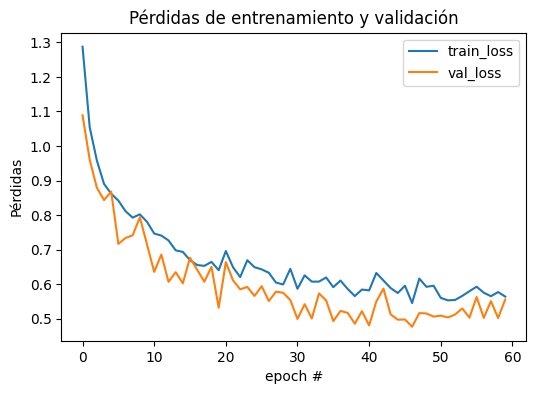

In [15]:
plt.figure(figsize=(6,4))
plt.plot(np.arange(0, len(history.history["loss"])), history.history["loss"], label= "train_loss")
plt.plot(np.arange(0, len(history.history["loss"])), history.history["val_loss"], label= "val_loss")
plt.title("Pérdidas de entrenamiento y validación")
plt.xlabel("epoch #")
plt.ylabel("Pérdidas")
plt.legend()
plt.show()#pruebas para saber las perdidas de los entrenamientos, en caso de que no debe volver a ejecutar

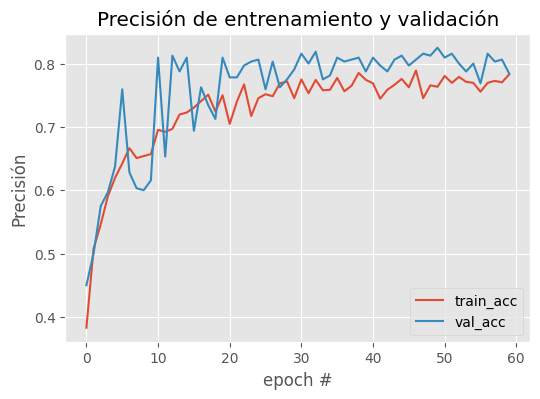

In [16]:
plt.style.use("ggplot")
plt.figure(figsize=(6,4))
plt.plot(np.arange(0, len(history.history["accuracy"])), history.history["accuracy"], label= "train_acc")
plt.plot(np.arange(0, len(history.history["accuracy"])), history.history["val_accuracy"], label= "val_acc")
plt.title("Precisión de entrenamiento y validación")
plt.xlabel("epoch #")
plt.ylabel("Precisión")
plt.legend()
plt.show() # está grafica se utiliza para saber que tanta precision tuvo el modelo, si las dos lineas están muy pegadas significa que el modelo si empato con  que son las imagenes de entrenamiento, en caso de que no se debe ejecutar desde el inicio y cambiar la presicion